# Introduction to Natural Language Processing: Assignment 1

In this assignment we'll practice word operations and text classifications.

- Please comment your code
- You can use built-in Python packages, scikit-learn and Pandas.
- Submissions are due **on Tuesdays at 23:59** and should be submitted **ONLY** on eCampus: **Assignmnets >> Student Submissions >> Assignment 1 (Deadline: 05.11.2024, at 23:59)**
- Name the file aproppriately "Assignment_1_\<Your_Name\>.ipynb".
- Please submit **ONLY** the Jupyter Notebook file.
- Please use relative path; Your code should work on my computer if the Jupyter Notebook and the file are both in the same directory.

Example: file_name = lemmatization-en.txt >> **DON'T use:** /Users/ComputerName/Username/Documents/.../lemmatization-en.txt

### Task 1.1 (2 points)

Write a function `extract_words_tokens(any_string)` that takes a string as input and returns two numbers:
1. num_words: The number of words in string
2. num_tokens: The number of tokens in string (Please use the character-based tokenization.)

**Hint:** The string can be a single word or a sentence and
 can contain some special charecters, such as: "!", ",", ":"

In [30]:
import re
def extract_words_tokens(any_string):
    words = re.split(r"[!,: -]+", any_string)
    tokens = set(words)

    return len(words), len(tokens)

mystr = "Somebody once told me, the world was gonna roll me: I ain't the shapest tool in the shed!"
num_words, num_tokens = extract_words_tokens(mystr)
print(mystr, ":", "num_words:", num_words, "and", "num_tokens:", num_tokens, "respectively")

Somebody once told me, the world was gonna roll me: I ain't the shapest tool in the shed! : num_words: 19 and num_tokens: 16 respectively


### Task 1.2 (4 points)

Write a function `lemmatize(any_string, file_name)` that takes as input any string and a file-name: `lemmatization-en.txt` (please download the file [here](https://github.com/michmech/lemmatization-lists/blob/master/lemmatization-en.txt). It's a tab separated corpus) and returns a dictionary with all words as keys and the lemma of the words as values.

**Hint:** To tokenize the string, please use the whitespace as the seperator. The string doesn't contain any special characters.

In [31]:
from pprint import pp
def lemmatize(any_string, file_name):
    tokens = set(any_string.split())
    full_dict = dict()
    with open(file_name, 'r') as f:
        for l in f.readlines():
            v, k = l.split()
            full_dict[k] = v
    dictionary_of_lemmatized_words = {token: (full_dict[token] if token in full_dict.keys() else token) for token in tokens}

    return dictionary_of_lemmatized_words

pp(lemmatize("somebody once told me the world was gonna roll me", "data/lemmatization-en.txt"))

{'the': 'the',
 'me': 'me',
 'was': 'be',
 'once': 'once',
 'somebody': 'somebody',
 'told': 'tell',
 'world': 'world',
 'gonna': 'gonna',
 'roll': 'roll'}


### Task 2 (1 point)

Create a DataFrame using the `polarity.txt` file and give name to the columns appropriately. (e.g., "Text", "Label")

In [32]:
#here comes your code

# here it comes:

import os

import pandas as pd

df = pd.read_csv("data/polarity.txt", sep='\t', names=["Text", "Label"])
df

                                                 Text Label
0   every now and then a movie comes along from a ...   pos
1   mtv films' _election , a high school comedy st...   pos
2   did anybody know this film existed a week befo...   pos
3                   the plot is deceptively simple .    pos
4   george washington carver high school is having...   pos
..                                                ...   ...
69  it also wrapped production two years ago and h...   neg
70                               whatever . . . skip    neg
71                                              it !    neg
72                       where's joblo coming from ?    neg
73  a nightmare of elm street 3 ( 7/10 ) - blair w...   pos

[74 rows x 2 columns]


### Task 2.1 (2 point)

Create a new column for the DataFrame that contains labels converted to numerical values instead of strings using the function: `apply()` and drop the original column afterwards.

Hint: The numarical values can be any meaningful values, e.g., pos >> 1 and neg >> 0

In [33]:
df["Label"] = pd.Series([1 if lbl == "pos" else 0 for lbl in df["Label"]], index=df.index)
df

                                                 Text  Label
0   every now and then a movie comes along from a ...      1
1   mtv films' _election , a high school comedy st...      1
2   did anybody know this film existed a week befo...      1
3                   the plot is deceptively simple .       1
4   george washington carver high school is having...      1
..                                                ...    ...
69  it also wrapped production two years ago and h...      0
70                               whatever . . . skip       0
71                                              it !       0
72                       where's joblo coming from ?       0
73  a nightmare of elm street 3 ( 7/10 ) - blair w...      1

[74 rows x 2 columns]


### Task 3 (7 points)

Write a function `create_count_and_probability` that takes a file (`corpus.txt`) as input and returns a csv file as output containing three columns:
1. Text
2. Count_Vector
3. Probability

Example:

For the line: `This document is the second document.`

The row in the csv file should contain:
`This document is the second document.`   `[0,2,0,1,0,1,1,0,1]`   `[1/6, 2/6, 1/6, 1/6, 1/6, 2/6]`

**Note**:

1. You should define your own function and not use e.g., CountVectorizer() which gives you the `count vector`, directly.

2. You can either use the whitespace in `split` as the seperator or use the `Regular Expression (re)` to extract the words, as follows:

```
import re
TEXT = "Hey, - How are you doing today!?"
words_list = re.findall(r"[\w']+", TEXT)
print(words_list)
```

3. To count the words, you can use e.g., the library: `collections`, more specifically `Counter`.

4. Please don't upload the output file. Your function should generate the file.

In [34]:
from collections import Counter
import re

from pandas import DataFrame

def create_count_and_probability(file_name):
    with open(file_name, 'r') as f:
        lines = [l.rstrip() for l in f.readlines()]

    documents = [[w.lower() for w in re.findall(r"[\w]+", line)] for line in lines]
    features = list({f for doc in documents for f in doc})

    rows = []
    for i, doc in enumerate(documents):
        c = Counter(doc)
        l = len(doc)

        count_vec = [c[word] for word in features]
        probs = [c[word] / l for word in doc]
        
        rows.append((lines[i], count_vec, probs))

    df = DataFrame(rows, columns=["Document", "WordVec", "Probabilities"])
    df.to_csv("Task3_output.csv", index=False)

    return df


create_count_and_probability("data/corpus.txt")

,Document,WordVec,Probabilities
0,This is the first document.,"[1, 0, 0, 1, 1, 1, 1, 0, 0]","[0.2, 0.2, 0.2, 0.2, 0.2]"
1,This document is the second document.,"[1, 0, 0, 2, 1, 1, 0, 0, 1]","[0.166667, 0.333333, 0.166667, 0.166667, 0.166..."
2,And this is the third one.,"[1, 1, 1, 0, 1, 1, 0, 1, 0]","[0.166667, 0.166667, 0.166667, 0.166667, 0.166..."
3,Is this the first document?,"[1, 0, 0, 1, 1, 1, 1, 0, 0]","[0.2, 0.2, 0.2, 0.2, 0.2]"


### Task 4 (8 points)

The goal of this task is to train and test classifiers provided in scikit-learn, using two datasets `rural.txt` and `science.txt`.

a) Each file (rural and science) contains sentence-wise documents. You should create a dataframe containing two columns: "Document" and " Class", as shown below. This dataframe will be used later as input for the vectorizer.

|Document                             |Class |
| ------------------------------------|----- |
|PM denies knowledge of AWB kickbacks | rural |
|The crocodile ancestor fossil, found...| science |


b) Remove stop words from the data and create two separate plots showing word frequency for documents in each label.

c) Split the data into train (70%) and test (30%) sets and use the following vectorization techniquess to train the two classifiers provided by scikit-learn:

- one-hot-encoding
- count vectorization

Classifiers:
- naive_bayes.GaussianNB()
- LogisticRegression()

**Hints:**
1. The Gaussian NB Classifier takes a dense matrix as input and the output of the vectorizer is a sparse matrix. Use my_matrix.toarray() for this conversion.
2. You can play around with various parameters in both the count-vectorizer and the classifier to get a better performance in terms of the accuracy. (In the exercise, we will discuss the accuracy of your model.)

In [35]:
# Here comes your code

import os

import pandas as pd

# ------ a) -------

# Find the txt files
for root, dirs, files in os.walk("."):
    if "science.txt" in files:
        science_location = os.path.abspath(os.path.join(root, "science.txt"))
    if "rural.txt" in files:
        rural_location = os.path.abspath(os.path.join(root, "rural.txt"))

# Read the txt files and store them into pandas dataframes. Use some russian to circumvent read_csv finding a seperator

df_science = pd.read_csv(science_location, sep="пельмени", header=None, names=["Document"], quoting=0, engine="python")

df_science["Class"] = "science"  # Adding class

df_rural = pd.read_csv(rural_location, sep="пельмени", header=None, names=["Document"], quoting=0, engine="python")

df_rural["Class"] = "rural"

df_combined = pd.concat([df_science, df_rural], ignore_index=True)  # COMBINE


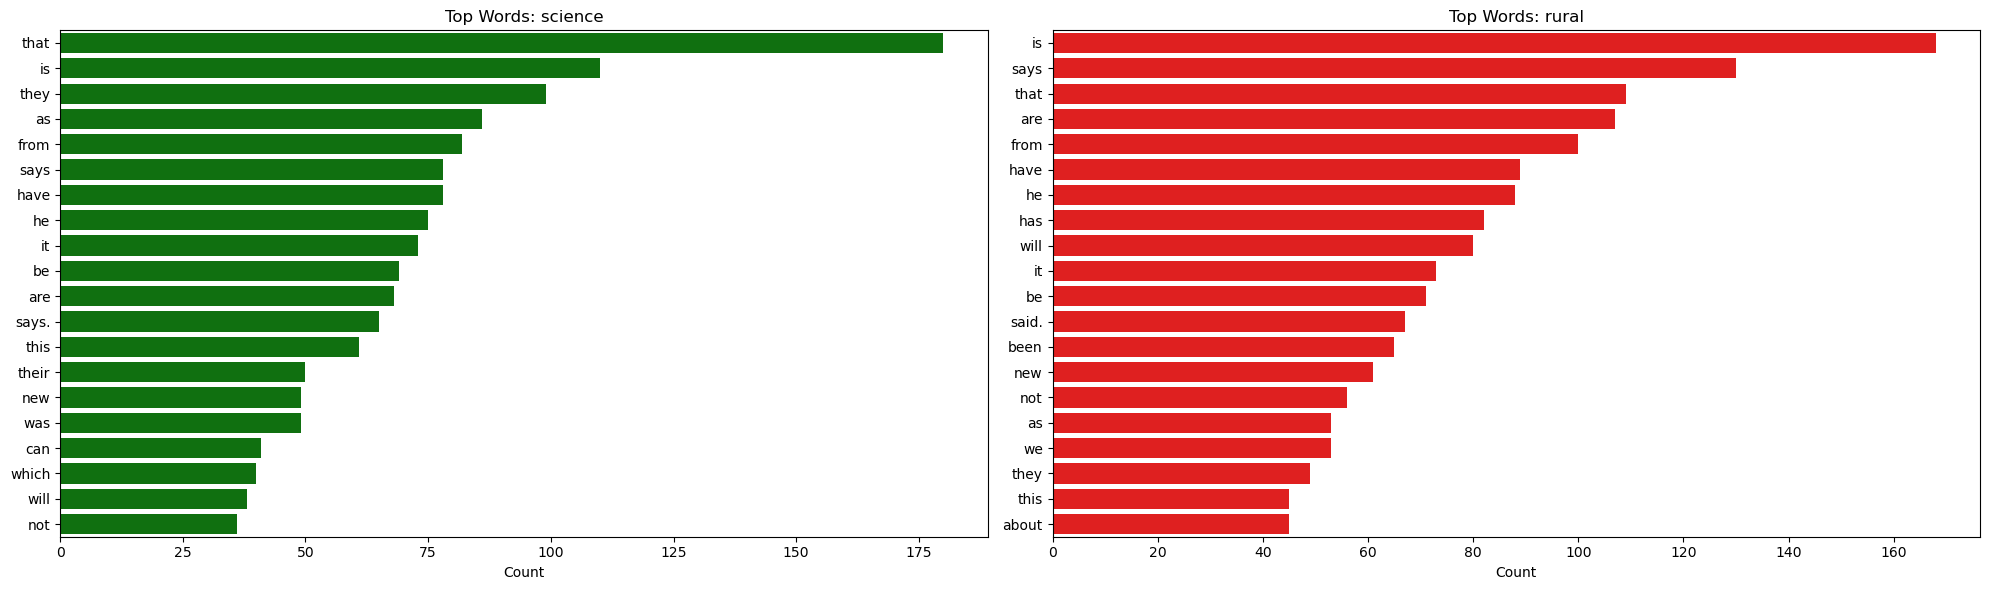

In [36]:
import string

import matplotlib.pyplot as plt
import seaborn as sns

# ------ b) -------

STOP_WORDS = ["a", "an", "the", "and", "or", "but", "in", "on", "at", "to", "for", "of", "with", "by"]


def remove_stopwords(text):
    words = text.lower().split() # unify the string to not count different capitalizations as seperate words
    filtered = [w for w in words if w not in STOP_WORDS and w not in string.punctuation] # get list of filtered words
    return " ".join(filtered) # join them in a string


df_combined["cleaned"] = df_combined["Document"].apply(remove_stopwords)

# Count words seperately for each class
classes = df_combined["Class"].unique() # rural and science
word_counts = {}

for cls in classes:
    word_counts[cls] = {}
    class_docs = df_combined[df_combined["Class"] == cls]
    for _, row in class_docs.iterrows():
        for word in row["cleaned"].split():
            if word not in word_counts[cls]:
                word_counts[cls][word] = 0
            word_counts[cls][word] += 1

# Plot top words for each class
fig, axes = plt.subplots(1, len(classes), figsize=(20, 6))

for i, cls in enumerate(classes):
    counts = word_counts[cls]
    sorted_words = sorted(counts.items(), key=lambda x: x[1], reverse=True)[:20]
    words = [w[0] for w in sorted_words]
    freqs = [w[1] for w in sorted_words]

    sns.barplot(x=freqs, y=words, ax=axes[i], color={"science": "green", "rural": "red"}[cls])
    axes[i].set_title(f"Top Words: {cls}")
    axes[i].set_xlabel("Count")
    axes[i].set_ylabel("")

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression  # Logistic regression
from sklearn.metrics import accuracy_score, classification_report  # For showing that stuff trained
from sklearn.model_selection import train_test_split  # For test splitting the data
from sklearn.naive_bayes import GaussianNB  # Naive bayes

# ------ c) -------


# Use the actual Class column as labels (one per document)
labels = df_combined["Class"].values
cleaned_docs = df_combined["cleaned"].values

# Split into train/test
X_train, X_test, y_train, y_test = train_test_split(
    cleaned_docs, labels, test_size=0.3, random_state=42, stratify=labels
)

# Encode labels
y_train_enc = np.array([0 if l == "science" else 1 for l in y_train])
y_test_enc = np.array([0 if l == "science" else 1 for l in y_test])

# Count Vectorization
count_vec = CountVectorizer(max_features=1000)
X_train_count = count_vec.fit_transform(X_train).toarray()
X_test_count = count_vec.transform(X_test).toarray()

# One-hot encoding (using CountVectorizer with binary=True as a proxy)
onehot_vec = CountVectorizer(binary=True, max_features=1000)
X_train_onehot = onehot_vec.fit_transform(X_train).toarray()
X_test_onehot = onehot_vec.transform(X_test).toarray()


# Train classifiers
def train_and_eval(name, X_train, X_test, y_train, y_test, classifier):
    clf = classifier()
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    print(f"\n{name}:")
    print(f"  Accuracy: {acc:.4f}")
    print(classification_report(y_test, y_pred, target_names=["science", "rural"]))
    return acc


# Count Vectorization + Naive Bayes
train_and_eval("Count Vectorization + GaussianNB", X_train_count, X_test_count, y_train_enc, y_test_enc, GaussianNB)

# Count Vectorization + Logistic Regression
train_and_eval(
    "Count Vectorization + LogisticRegression", X_train_count, X_test_count, y_train_enc, y_test_enc, LogisticRegression
)

# One-hot + Naive Bayes
train_and_eval("One-hot Encoding + GaussianNB", X_train_onehot, X_test_onehot, y_train_enc, y_test_enc, GaussianNB)

# One-hot + Logistic Regression
train_and_eval(
    "One-hot Encoding + LogisticRegression", X_train_onehot, X_test_onehot, y_train_enc, y_test_enc, LogisticRegression
)



Count Vectorization + GaussianNB:
  Accuracy: 0.8665
              precision    recall  f1-score   support

     science       0.93      0.80      0.86       172
       rural       0.82      0.93      0.87       165

    accuracy                           0.87       337
   macro avg       0.87      0.87      0.87       337
weighted avg       0.87      0.87      0.87       337


Count Vectorization + LogisticRegression:
  Accuracy: 0.8843
              precision    recall  f1-score   support

     science       0.87      0.91      0.89       172
       rural       0.90      0.86      0.88       165

    accuracy                           0.88       337
   macro avg       0.89      0.88      0.88       337
weighted avg       0.88      0.88      0.88       337


One-hot Encoding + GaussianNB:
  Accuracy: 0.8487
              precision    recall  f1-score   support

     science       0.92      0.77      0.84       172
       rural       0.79      0.93      0.86       165

    accuracy   

0.8902077151335311